In [ ]:
# ============================================================
# 01b_host_eda_deep.ipynb — 환경 설정 (config.py 자동 로드)
# ============================================================
import sys
import matplotlib.patches as mpatches
from pathlib import Path

# 프로젝트 루트를 sys.path에 추가 (실행 위치 무관)
for _p in [Path.cwd(), Path.cwd().parent]:
    if (_p / 'config.py').exists():
        sys.path.insert(0, str(_p))
        break

from config import *  # 모든 상수·경로·KPI·시각화 설정·헬퍼 함수 일괄 적용

# ── 데이터 로드 및 파생 변수 추가
df    = load_raw()
df_ao = load_raw(active_only=True)
df_ao = add_kpi_features(df_ao)   # revpar_trend, log_ttm_revpar, is_active_operating

print(f'✅ 데이터 로드: {len(df):,}건 (Active+Oper: {len(df_ao):,}건)')
print(f'\n📋 이 노트북의 분석 범위 (01_host_eda 미분석 영역):')
print('  A. ADR × 점유율 분해 — RevPAR 드라이버 분석')
print('  B. num_reviews 심층 — 예약 빈도 신호')
print('  C. 수용 인원(guests/baths) 분석')
print('  D. POI 유형별 위치 효과')
print('  E. RevPAR 트렌드(성장/하락) 분석')
print('  F. 전체 수치형 상관관계 히트맵')
print('  G. 고성과 vs 저성과 프로필 비교')
print('  H. extra_guest_fee 실제 금액 효과')
print('  I. listing_type Top 15 분석')
print('  J. 다변량 인터랙션 — room_type × superhost × photos')

## A. ADR × 점유율 분해 — RevPAR 드라이버 분석

**RevPAR = ADR × 점유율** 이므로 두 구성 요소 중 어느 쪽이 더 RevPAR에 기여하는지가 핵심입니다.

**분석 목표:** 4분면(Quadrant) 분류로 숙소를 "고가-고점유", "고가-저점유", "저가-고점유", "저가-저점유" 네 유형으로 분리 후 각 유형의 RevPAR 수준 비교.

In [2]:
# ADR × 점유율 4분면 분류
adr_med = df_ao['ttm_avg_rate'].median()
occ_med = df_ao['ttm_occupancy'].median()

def quadrant(row):
    h_adr = row['ttm_avg_rate'] >= adr_med
    h_occ = row['ttm_occupancy'] >= occ_med
    if h_adr and h_occ:     return '고가-고점유'
    elif h_adr and not h_occ: return '고가-저점유'
    elif not h_adr and h_occ: return '저가-고점유'
    else:                   return '저가-저점유'

df_ao['quadrant'] = df_ao.apply(quadrant, axis=1)

quad_stats = df_ao.groupby('quadrant')['ttm_revpar'].agg(
    median='median', count='count'
).sort_values('median', ascending=False)

print('=== 4분면별 RevPAR 중위값 ===\n')
print(quad_stats.assign(median=quad_stats['median'].map(lambda x: f'₩{x:,.0f}')).to_string())
print(f'\n기준선: ADR 중위값 = ₩{adr_med:,.0f} | 점유율 중위값 = {occ_med:.2f}')

=== 4분면별 RevPAR 중위값 ===

            median  count
quadrant                 
고가-고점유    ₩108,094   3672
저가-고점유     ₩48,359   3534
고가-저점유     ₩46,277   3528
저가-저점유     ₩16,610   3665

기준선: ADR 중위값 = ₩102,321 | 점유율 중위값 = 0.51


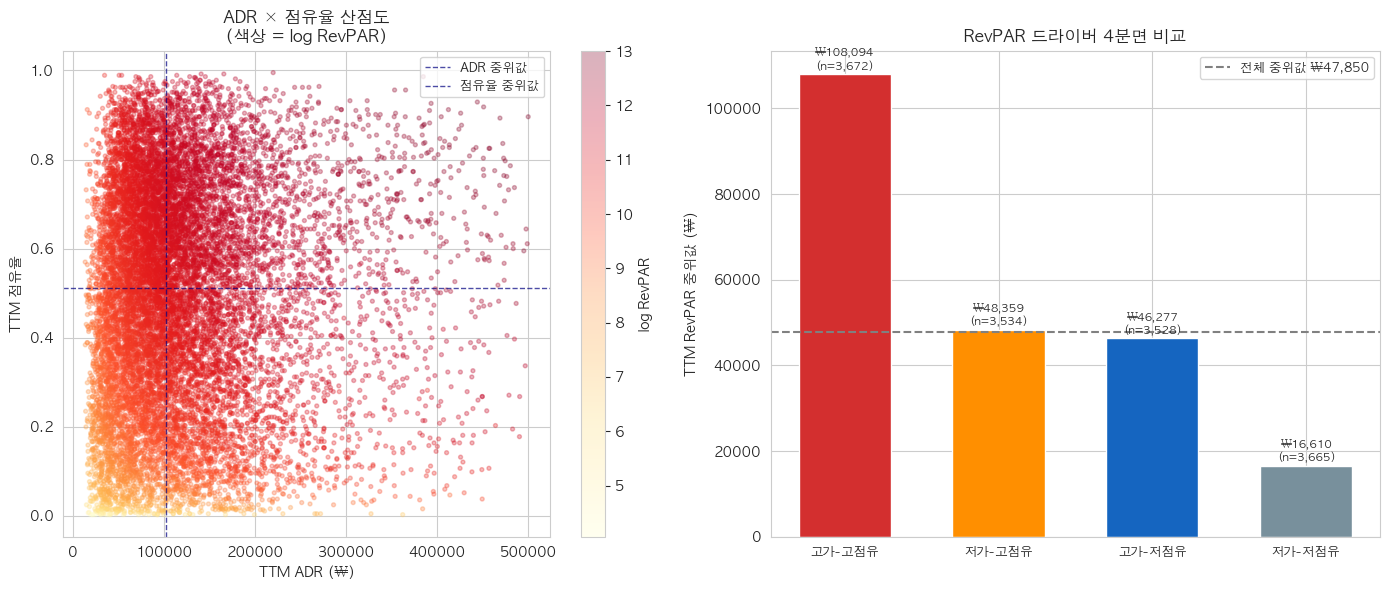

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 산점도: ADR vs 점유율 (RevPAR 색상)
df_plot = df_ao[(df_ao['ttm_avg_rate'] < 500000) & (df_ao['ttm_occupancy'] > 0)]
sc = axes[0].scatter(
    df_plot['ttm_avg_rate'], df_plot['ttm_occupancy'],
    c=np.log1p(df_plot['ttm_revpar']), cmap='YlOrRd',
    alpha=0.3, s=8
)
axes[0].axvline(adr_med, color='navy', linestyle='--', linewidth=1, alpha=0.7, label=f'ADR 중위값')
axes[0].axhline(occ_med, color='navy', linestyle='--', linewidth=1, alpha=0.7, label=f'점유율 중위값')
axes[0].set_title('ADR × 점유율 산점도\n(색상 = log RevPAR)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('TTM ADR (₩)')
axes[0].set_ylabel('TTM 점유율')
axes[0].legend(fontsize=9)
plt.colorbar(sc, ax=axes[0], label='log RevPAR')

# 4분면별 RevPAR 막대
q_order = ['고가-고점유', '저가-고점유', '고가-저점유', '저가-저점유']
q_colors = ['#D32F2F', '#FF8F00', '#1565C0', '#78909C']
q_vals = [quad_stats.loc[q, 'median'] for q in q_order if q in quad_stats.index]
q_cnts = [int(quad_stats.loc[q, 'count']) for q in q_order if q in quad_stats.index]
valid_q = [q for q in q_order if q in quad_stats.index]

bars = axes[1].bar(valid_q, q_vals, color=q_colors[:len(valid_q)], width=0.6, edgecolor='white')
axes[1].axhline(KPI_REVPAR_ACTIVE_MEDIAN, color='gray', linestyle='--',
                 label=f'전체 중위값 ₩{KPI_REVPAR_ACTIVE_MEDIAN:,.0f}')
axes[1].set_title('RevPAR 드라이버 4분면 비교', fontsize=12, fontweight='bold')
axes[1].set_ylabel('TTM RevPAR 중위값 (₩)')
for bar, val, cnt in zip(bars, q_vals, q_cnts):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
                  f'₩{val:,.0f}\n(n={cnt:,})', ha='center', va='bottom', fontsize=8, fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].tick_params(axis='x', labelsize=9)

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01b_A_adr_occ_quadrant.png', dpi=100, bbox_inches='tight')
plt.show()

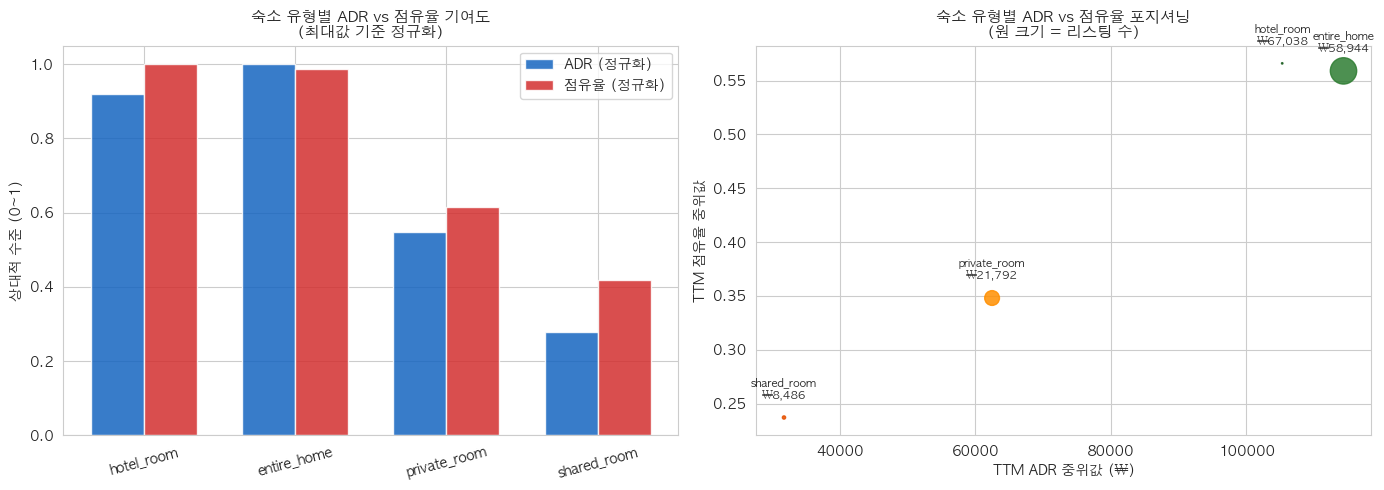


=== 숙소 유형별 ADR / 점유율 / RevPAR 중위값 ===
              adr_median  occ_median  revpar_median  count
room_type                                                 
hotel_room    105272.769       0.566       67037.65     32
entire_home   114315.140       0.559       58944.00  10800
private_room   62471.828       0.348       21791.80   3401
shared_room    31774.113       0.237        8486.15    166


In [4]:
# room_type별 ADR vs 점유율 기여도
rt_driver = df_ao.groupby('room_type').agg(
    adr_median=('ttm_avg_rate', 'median'),
    occ_median=('ttm_occupancy', 'median'),
    revpar_median=('ttm_revpar', 'median'),
    count=('ttm_revpar', 'count')
).sort_values('revpar_median', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 유형별 ADR 비교
x = np.arange(len(rt_driver))
w = 0.35
adr_norm = rt_driver['adr_median'] / rt_driver['adr_median'].max()
occ_norm = rt_driver['occ_median'] / rt_driver['occ_median'].max()

axes[0].bar(x - w/2, adr_norm, w, label='ADR (정규화)', color='#1565C0', alpha=0.85)
axes[0].bar(x + w/2, occ_norm, w, label='점유율 (정규화)', color='#D32F2F', alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(rt_driver.index, rotation=15)
axes[0].set_title('숙소 유형별 ADR vs 점유율 기여도\n(최대값 기준 정규화)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('상대적 수준 (0~1)')
axes[0].legend()

# RevPAR 분해 스택 바
# RevPAR = ADR × Occupancy → log scale에서 더하기
rt_driver['log_adr'] = np.log1p(rt_driver['adr_median'])
rt_driver['revpar_from_adr_pct'] = rt_driver['log_adr'] / np.log1p(rt_driver['revpar_median'])

axes[1].scatter(rt_driver['adr_median'], rt_driver['occ_median'],
                 s=rt_driver['count'] / 30, c=['#1B5E20','#2E7D32','#FF8F00','#E65100'],
                 alpha=0.85, zorder=3)
for rt, row in rt_driver.iterrows():
    axes[1].annotate(f"{rt}\n₩{row['revpar_median']:,.0f}",
                      (row['adr_median'], row['occ_median']),
                      fontsize=8, ha='center', va='bottom',
                      xytext=(0, 12), textcoords='offset points')
axes[1].set_title('숙소 유형별 ADR vs 점유율 포지셔닝\n(원 크기 = 리스팅 수)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('TTM ADR 중위값 (₩)')
axes[1].set_ylabel('TTM 점유율 중위값')

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01b_A_rt_adr_occ_driver.png', dpi=100, bbox_inches='tight')
plt.show()
print('\n=== 숙소 유형별 ADR / 점유율 / RevPAR 중위값 ===')
print(rt_driver[['adr_median','occ_median','revpar_median','count']].round(3).to_string())

## B. num_reviews 심층 분석 — 예약 빈도 신호

`num_reviews`는 예약 횟수의 proxy 지표입니다. 리뷰를 많이 받은 숙소는 그만큼 자주 예약된 것을 의미하므로, 리뷰 수가 많을수록 점유율이 높고 RevPAR도 높을 것으로 가설을 세울 수 있습니다. 단, 일정 수준 이상에서는 한계 효과가 체감될 수 있습니다.

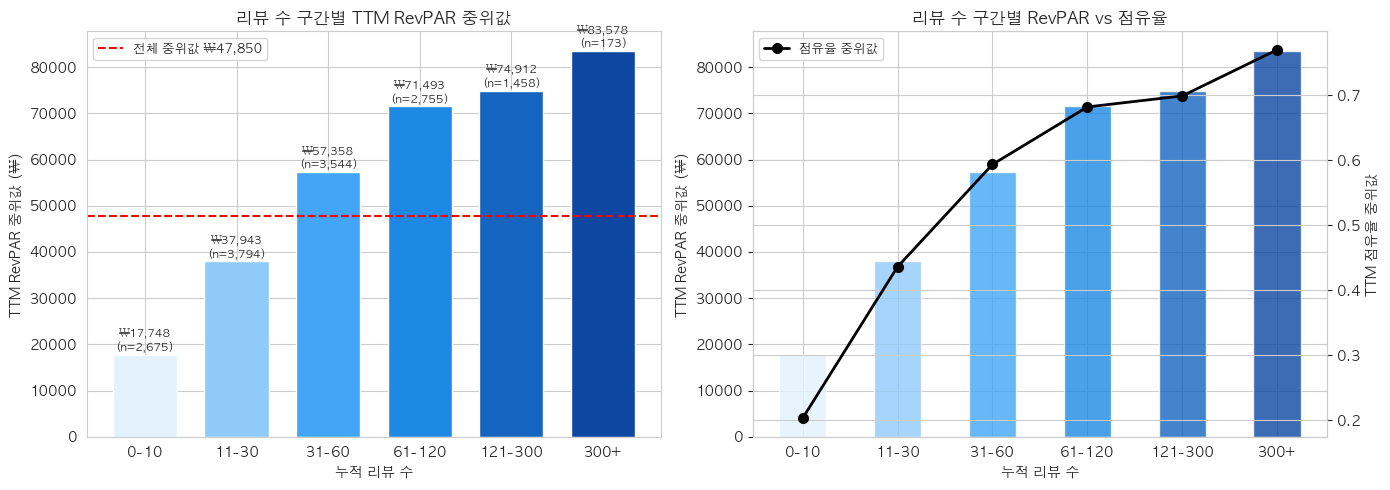


=== 리뷰 수 구간별 통계 ===
         revpar_med  occ_med  count
리뷰수_구간                             
0-10       17748.10   0.2030   2675
11-30      37943.15   0.4360   3794
31-60      57357.55   0.5935   3544
61-120     71493.40   0.6820   2755
121-300    74911.95   0.6990   1458
300+       83578.10   0.7700    173


In [5]:
# num_reviews 구간별 RevPAR
bins_rev = [0, 10, 30, 60, 120, 300, 3300]
labels_rev = ['0-10', '11-30', '31-60', '61-120', '121-300', '300+']
df_ao['리뷰수_구간'] = pd.cut(df_ao['num_reviews'], bins=bins_rev, labels=labels_rev)

rev_stats = df_ao.groupby('리뷰수_구간', observed=False).agg(
    revpar_med=('ttm_revpar', 'median'),
    occ_med=('ttm_occupancy', 'median'),
    count=('ttm_revpar', 'count')
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# RevPAR by review count
colors_rev = ['#E3F2FD','#90CAF9','#42A5F5','#1E88E5','#1565C0','#0D47A1']
bars = axes[0].bar(rev_stats.index.astype(str), rev_stats['revpar_med'],
                    color=colors_rev, width=0.7, edgecolor='white')
axes[0].axhline(KPI_REVPAR_ACTIVE_MEDIAN, color='red', linestyle='--', linewidth=1.5,
                 label=f'전체 중위값 ₩{KPI_REVPAR_ACTIVE_MEDIAN:,.0f}')
axes[0].set_title('리뷰 수 구간별 TTM RevPAR 중위값', fontsize=12, fontweight='bold')
axes[0].set_xlabel('누적 리뷰 수')
axes[0].set_ylabel('TTM RevPAR 중위값 (₩)')
for bar, row in zip(bars, rev_stats.itertuples()):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 400,
                  f'₩{row.revpar_med:,.0f}\n(n={row.count:,})',
                  ha='center', va='bottom', fontsize=8)
axes[0].legend(fontsize=9)

# 점유율 같이 보기
ax2 = axes[1].twinx()
bars2 = axes[1].bar(rev_stats.index.astype(str), rev_stats['revpar_med'],
                     color=colors_rev, width=0.5, alpha=0.8)
ax2.plot(rev_stats.index.astype(str), rev_stats['occ_med'],
          'ko-', markersize=7, linewidth=2, label='점유율 중위값')
axes[1].set_title('리뷰 수 구간별 RevPAR vs 점유율', fontsize=12, fontweight='bold')
axes[1].set_xlabel('누적 리뷰 수')
axes[1].set_ylabel('TTM RevPAR 중위값 (₩)')
ax2.set_ylabel('TTM 점유율 중위값')
ax2.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01b_B_reviews_revpar.png', dpi=100, bbox_inches='tight')
plt.show()
print('\n=== 리뷰 수 구간별 통계 ===')
print(rev_stats.to_string())

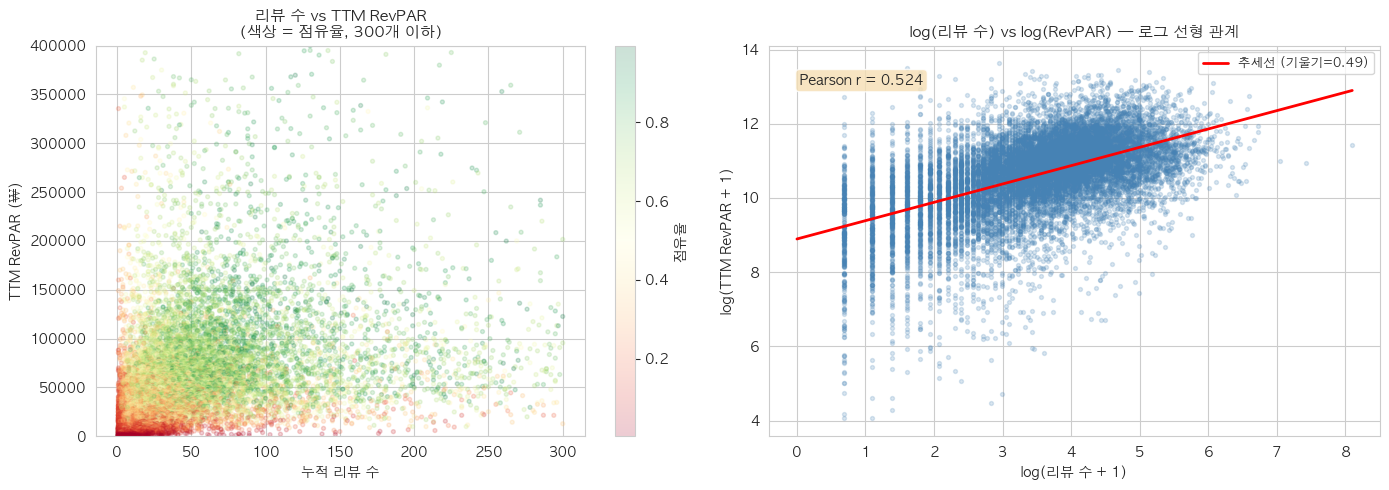

In [6]:
# 리뷰 수 vs RevPAR 상관관계 (연속)
df_plot_rev = df_ao[df_ao['num_reviews'] <= 300].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 산점도
sc = axes[0].scatter(
    df_plot_rev['num_reviews'], df_plot_rev['ttm_revpar'],
    alpha=0.2, s=8, c=df_plot_rev['ttm_occupancy'], cmap='RdYlGn'
)
axes[0].set_ylim(0, 400000)
axes[0].set_title('리뷰 수 vs TTM RevPAR\n(색상 = 점유율, 300개 이하)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('누적 리뷰 수')
axes[0].set_ylabel('TTM RevPAR (₩)')
plt.colorbar(sc, ax=axes[0], label='점유율')

# 로그 스케일 scatter
df_plot_log = df_ao[(df_ao['num_reviews'] > 0) & (df_ao['ttm_revpar'] > 0)].copy()
axes[1].scatter(
    np.log1p(df_plot_log['num_reviews']), np.log1p(df_plot_log['ttm_revpar']),
    alpha=0.2, s=8, color='steelblue'
)
# 추세선
z = np.polyfit(np.log1p(df_plot_log['num_reviews']), np.log1p(df_plot_log['ttm_revpar']), 1)
p = np.poly1d(z)
x_line = np.linspace(0, np.log1p(3300), 100)
axes[1].plot(x_line, p(x_line), 'r-', linewidth=2, label=f'추세선 (기울기={z[0]:.2f})')
axes[1].set_title('log(리뷰 수) vs log(RevPAR) — 로그 선형 관계', fontsize=11, fontweight='bold')
axes[1].set_xlabel('log(리뷰 수 + 1)')
axes[1].set_ylabel('log(TTM RevPAR + 1)')
axes[1].legend(fontsize=9)

# 피어슨 상관계수
corr_log = np.corrcoef(
    np.log1p(df_plot_log['num_reviews']),
    np.log1p(df_plot_log['ttm_revpar'])
)[0, 1]
axes[1].text(0.05, 0.9, f'Pearson r = {corr_log:.3f}',
              transform=axes[1].transAxes, fontsize=10,
              bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01b_B_reviews_scatter.png', dpi=100, bbox_inches='tight')
plt.show()

## C. 수용 인원 분석 — guests / baths / beds

`guests_group`(1~6 vs 7+), `baths_group`(Normal vs Large), `beds` 수가 RevPAR에 미치는 영향을 분석합니다. 대형 숙소가 더 높은 ADR을 보이는지, 또는 점유율이 낮아 RevPAR이 오히려 낮아지는지 확인합니다.

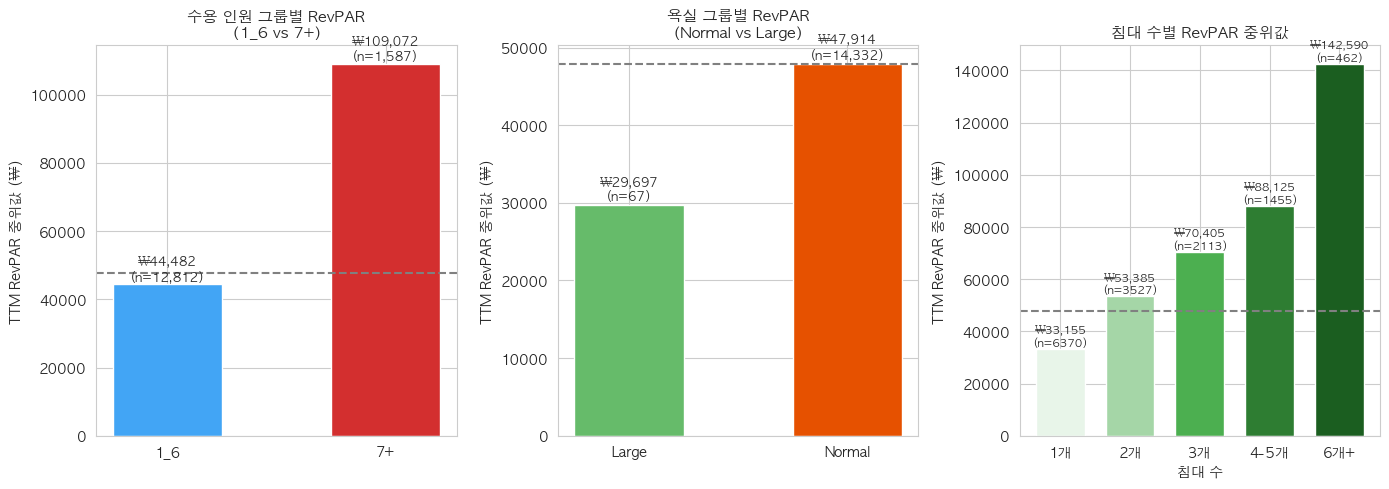

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

# guests_group
gg_stats = df_ao.groupby('guests_group')['ttm_revpar'].agg(
    median='median', count='count'
)
bars0 = axes[0].bar(gg_stats.index, gg_stats['median'],
                     color=['#42A5F5', '#D32F2F'], width=0.5)
axes[0].axhline(KPI_REVPAR_ACTIVE_MEDIAN, color='gray', linestyle='--')
axes[0].set_title('수용 인원 그룹별 RevPAR\n(1_6 vs 7+)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('TTM RevPAR 중위값 (₩)')
for bar, row in zip(bars0, gg_stats.itertuples()):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 400,
                  f'₩{row.median:,.0f}\n(n={row.count:,})',
                  ha='center', va='bottom', fontsize=9, fontweight='bold')

# baths_group
bg_stats = df_ao.groupby('baths_group')['ttm_revpar'].agg(
    median='median', count='count'
)
bars1 = axes[1].bar(bg_stats.index, bg_stats['median'],
                     color=['#66BB6A', '#E65100'], width=0.5)
axes[1].axhline(KPI_REVPAR_ACTIVE_MEDIAN, color='gray', linestyle='--')
axes[1].set_title('욕실 그룹별 RevPAR\n(Normal vs Large)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('TTM RevPAR 중위값 (₩)')
for bar, row in zip(bars1, bg_stats.itertuples()):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 400,
                  f'₩{row.median:,.0f}\n(n={row.count:,})',
                  ha='center', va='bottom', fontsize=9, fontweight='bold')

# 침대 수 구간별 (continuous beds)
df_ao['beds_bin'] = pd.cut(df_ao['beds'], bins=[0,1,2,3,5,50],
                             labels=['1개', '2개', '3개', '4-5개', '6개+'])
beds_stats = df_ao.groupby('beds_bin', observed=False)['ttm_revpar'].agg(
    median='median', count='count'
)
colors_beds = ['#E8F5E9', '#A5D6A7', '#4CAF50', '#2E7D32', '#1B5E20']
bars2 = axes[2].bar(beds_stats.index.astype(str), beds_stats['median'],
                     color=colors_beds, width=0.7)
axes[2].axhline(KPI_REVPAR_ACTIVE_MEDIAN, color='gray', linestyle='--')
axes[2].set_title('침대 수별 RevPAR 중위값', fontsize=11, fontweight='bold')
axes[2].set_xlabel('침대 수')
axes[2].set_ylabel('TTM RevPAR 중위값 (₩)')
for bar, row in zip(bars2, beds_stats.itertuples()):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 400,
                  f'₩{row.median:,.0f}\n(n={row.count})',
                  ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01b_C_capacity_revpar.png', dpi=100, bbox_inches='tight')
plt.show()

=== guests_group별 ADR / 점유율 / RevPAR ===
                    adr   occ     revpar  count
guests_group                                   
1_6            94986.55  0.51   44482.15  12812
7+            212440.03  0.52  109072.00   1587


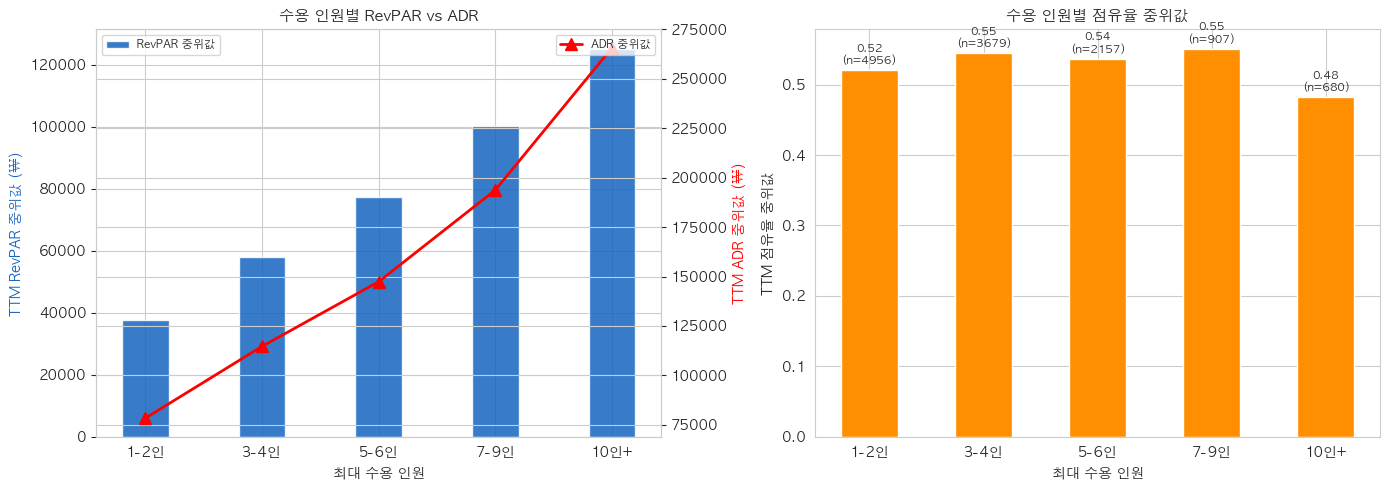

In [8]:
# 수용 인원 그룹별 ADR / 점유율 / RevPAR 비교
gg_detail = df_ao.groupby('guests_group').agg(
    adr=('ttm_avg_rate', 'median'),
    occ=('ttm_occupancy', 'median'),
    revpar=('ttm_revpar', 'median'),
    count=('ttm_revpar', 'count')
)
print('=== guests_group별 ADR / 점유율 / RevPAR ===')
print(gg_detail.round(2).to_string())

# guests(연속) vs RevPAR
df_ao['guests_bin'] = pd.cut(df_ao['guests'], bins=[0,2,4,6,9,17],
                              labels=['1-2인', '3-4인', '5-6인', '7-9인', '10인+'])
# DataFrame agg (not Series) to include multiple columns
gb_stats = df_ao.groupby('guests_bin', observed=False).agg(
    median=('ttm_revpar', 'median'),
    count=('ttm_revpar', 'count'),
    adr=('ttm_avg_rate', 'median')
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(len(gb_stats))
w = 0.4
ax2 = axes[0].twinx()
axes[0].bar(x, gb_stats['median'], w, label='RevPAR 중위값', color='#1565C0', alpha=0.85)
ax2.plot(x, gb_stats['adr'], 'r^-', markersize=8, linewidth=2, label='ADR 중위값')
axes[0].set_xticks(x)
axes[0].set_xticklabels(gb_stats.index.astype(str))
axes[0].set_title('수용 인원별 RevPAR vs ADR', fontsize=11, fontweight='bold')
axes[0].set_xlabel('최대 수용 인원')
axes[0].set_ylabel('TTM RevPAR 중위값 (₩)', color='#1565C0')
ax2.set_ylabel('TTM ADR 중위값 (₩)', color='red')
axes[0].legend(loc='upper left', fontsize=8)
ax2.legend(loc='upper right', fontsize=8)

# 점유율
gb_occ = df_ao.groupby('guests_bin', observed=False)['ttm_occupancy'].median()
axes[1].bar(gb_occ.index.astype(str), gb_occ.values, color='#FF8F00', width=0.5)
axes[1].set_title('수용 인원별 점유율 중위값', fontsize=11, fontweight='bold')
axes[1].set_xlabel('최대 수용 인원')
axes[1].set_ylabel('TTM 점유율 중위값')
for i, (label, val) in enumerate(zip(gb_occ.index.astype(str), gb_occ.values)):
    cnt = int(gb_stats.loc[label, 'count']) if label in gb_stats.index else 0
    axes[1].text(i, val + 0.005, f'{val:.2f}\n(n={cnt})', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01b_C_guests_adr_occ.png', dpi=100, bbox_inches='tight')
plt.show()

## D. POI 유형별 위치 효과 분석

01_host_eda에서는 **POI 거리**만 분석했습니다. 이 섹션에서는 **POI 유형**(관광지, 음식점, 쇼핑 등)이 RevPAR에 미치는 영향을 분석합니다. 또한 POI 유형 × 거리 교차 분석으로 위치 프리미엄의 구조를 파악합니다.

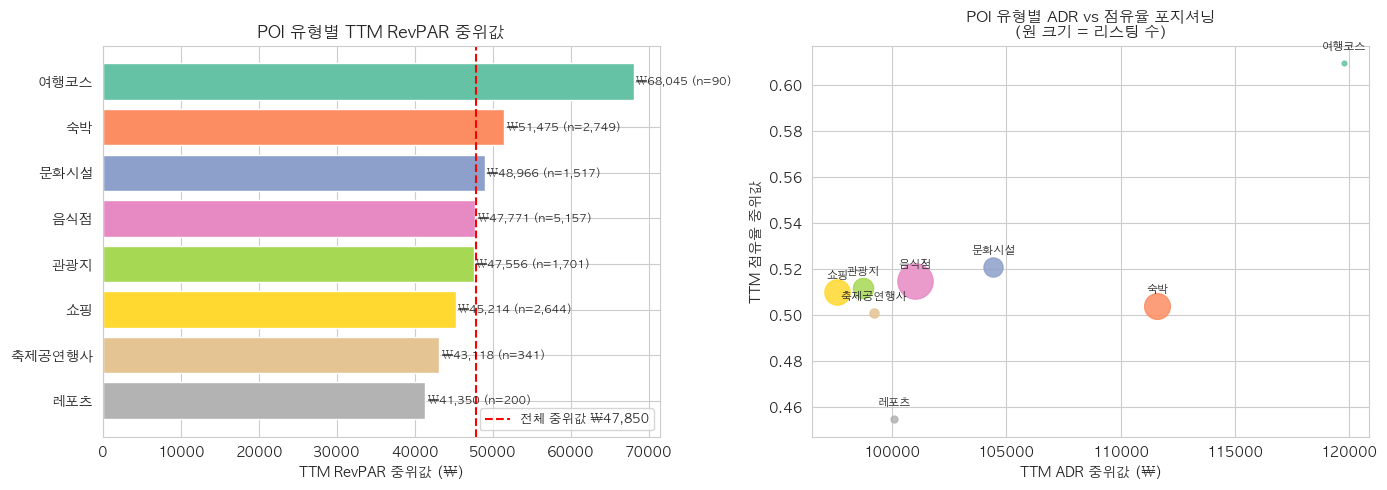


=== POI 유형별 통계 ===
                       revpar_med        adr_med  occ_med  count
nearest_poi_type_name                                           
여행코스                     68044.75  119768.989182   0.6095     90
숙박                       51474.70  111596.344246   0.5040   2749
문화시설                     48966.10  104437.328354   0.5210   1517
음식점                      47770.60  101022.294714   0.5150   5157
관광지                      47555.50   98721.468247   0.5120   1701
쇼핑                       45214.40   97618.513224   0.5100   2644
축제공연행사                   43118.30   99201.527806   0.5010    341
레포츠                      41350.10  100090.196928   0.4550    200


In [9]:
# POI 유형별 RevPAR 분포
poi_stats = df_ao.groupby('nearest_poi_type_name').agg(
    revpar_med=('ttm_revpar', 'median'),
    adr_med=('ttm_avg_rate', 'median'),
    occ_med=('ttm_occupancy', 'median'),
    count=('ttm_revpar', 'count')
).sort_values('revpar_med', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# RevPAR 막대
colors_poi = sns.color_palette('Set2', len(poi_stats))
bars = axes[0].barh(poi_stats.index[::-1], poi_stats['revpar_med'][::-1],
                     color=colors_poi[::-1], edgecolor='white')
axes[0].axvline(KPI_REVPAR_ACTIVE_MEDIAN, color='red', linestyle='--', linewidth=1.5,
                 label=f'전체 중위값 ₩{KPI_REVPAR_ACTIVE_MEDIAN:,.0f}')
axes[0].set_title('POI 유형별 TTM RevPAR 중위값', fontsize=12, fontweight='bold')
axes[0].set_xlabel('TTM RevPAR 중위값 (₩)')
for bar, row in zip(bars, poi_stats.iloc[::-1].itertuples()):
    axes[0].text(bar.get_width() + 300, bar.get_y() + bar.get_height()/2,
                  f'₩{row.revpar_med:,.0f} (n={row.count:,})',
                  va='center', fontsize=8)
axes[0].legend(fontsize=9)

# ADR vs 점유율 bubble
for i, (poi_type, row) in enumerate(poi_stats.iterrows()):
    axes[1].scatter(row['adr_med'], row['occ_med'],
                     s=row['count']/8, color=colors_poi[i], alpha=0.85, zorder=3)
    axes[1].annotate(poi_type, (row['adr_med'], row['occ_med']),
                      fontsize=8, ha='center', va='bottom',
                      xytext=(0, 8), textcoords='offset points')
axes[1].set_title('POI 유형별 ADR vs 점유율 포지셔닝\n(원 크기 = 리스팅 수)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('TTM ADR 중위값 (₩)')
axes[1].set_ylabel('TTM 점유율 중위값')

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01b_D_poi_type_revpar.png', dpi=100, bbox_inches='tight')
plt.show()
print('\n=== POI 유형별 통계 ===')
print(poi_stats.to_string())

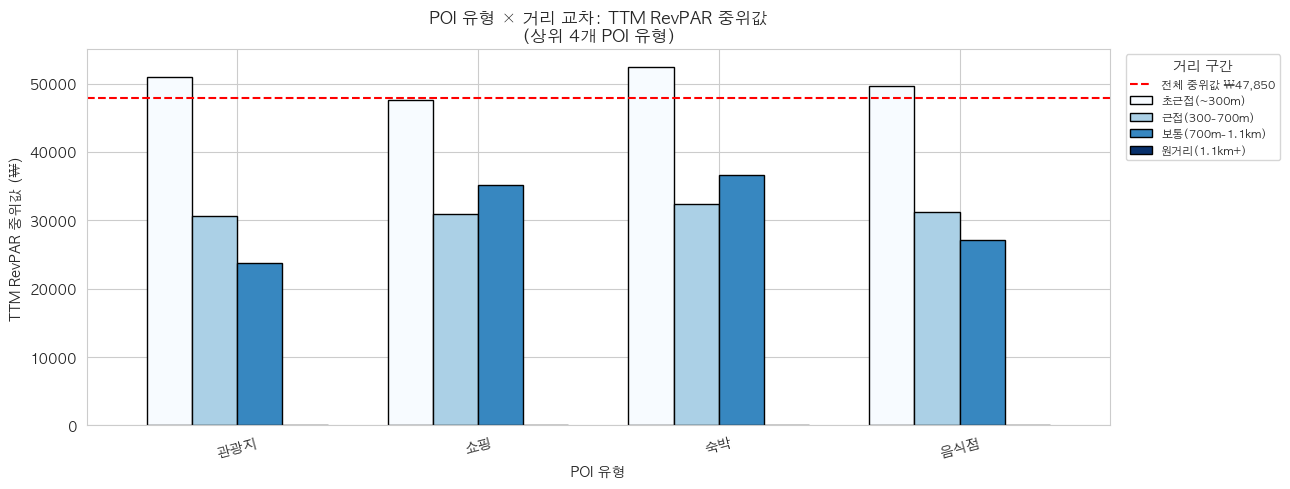

In [22]:
# POI 유형 × 거리 교차 분석
df_ao['poi_dist_cat'] = pd.cut(
    df_ao['nearest_poi_dist_km'],
    bins=[0, 0.3, 0.7, 1.1, 2.0],
    labels=['초근접(~300m)', '근접(300-700m)', '보통(700m-1.1km)', '원거리(1.1km+)']
)

# POI 유형별 거리 효과 — 상위 4개 유형만
top4_poi = poi_stats.nlargest(4, 'count').index.tolist()
df_cross = df_ao[df_ao['nearest_poi_type_name'].isin(top4_poi)]

cross_pivot = df_cross.groupby(
    ['nearest_poi_type_name', 'poi_dist_cat'], observed=False
)['ttm_revpar'].median().unstack()

fig, ax = plt.subplots(figsize=(13, 5))
cross_pivot.plot(kind='bar', ax=ax, colormap='Blues', width=0.75, edgecolor='black')
ax.axhline(KPI_REVPAR_ACTIVE_MEDIAN, color='red', linestyle='--', linewidth=1.5,
            label=f'전체 중위값 ₩{KPI_REVPAR_ACTIVE_MEDIAN:,.0f}')
ax.set_title('POI 유형 × 거리 교차: TTM RevPAR 중위값\n(상위 4개 POI 유형)', fontsize=12, fontweight='bold')
ax.set_xlabel('POI 유형')
ax.set_ylabel('TTM RevPAR 중위값 (₩)')
ax.tick_params(axis='x', rotation=15)
ax.legend(title='거리 구간', bbox_to_anchor=(1.01, 1), fontsize=8)

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01b_D_poi_type_dist_cross.png', dpi=100, bbox_inches='tight')
plt.show()

## E. RevPAR 트렌드 분석 — 성장 vs 하락

`revpar_trend = (l90d_revpar - ttm_revpar/4) / (ttm_revpar/4 + 1e-6)` — 최근 90일이 연간 평균 분기 RevPAR 대비 얼마나 더 높은지(성장) 또는 낮은지(하락)를 나타냅니다.

**목표:** 성장 중인 숙소 vs 하락 중인 숙소의 특성 차이를 파악하여 어떤 호스트 행동이 모멘텀 지속에 기여하는지 탐색합니다.

=== RevPAR 트렌드 분류 ===
  하락(trend<0): 1,040건 (7.2%)
  완만한 성장(0-2x): 3,276건 (22.8%)
  강한 성장(2-5x): 8,195건 (56.9%)
  급성장(5x+): 1,888건 (13.1%)


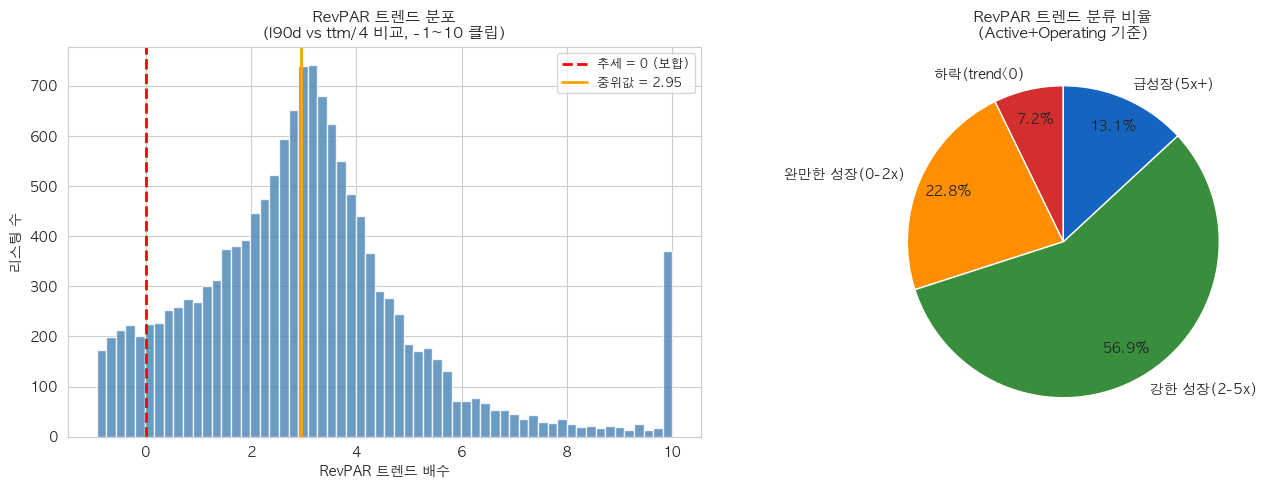

In [11]:
# 트렌드 분류 (상위/중위/하위)
df_ao['trend_cat'] = pd.cut(
    df_ao['revpar_trend'],
    bins=[-2, 0, 2, 5, 16],
    labels=['하락(trend<0)', '완만한 성장(0-2x)', '강한 성장(2-5x)', '급성장(5x+)']
)

trend_dist = df_ao['trend_cat'].value_counts().sort_index()
print('=== RevPAR 트렌드 분류 ===')
for cat, cnt in trend_dist.items():
    print(f'  {cat}: {cnt:,}건 ({cnt/len(df_ao)*100:.1f}%)')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 트렌드 분포
df_ao['revpar_trend_clipped'] = df_ao['revpar_trend'].clip(-1, 10)
axes[0].hist(df_ao['revpar_trend_clipped'], bins=60, color='steelblue', alpha=0.8, edgecolor='white')
axes[0].axvline(0, color='red', linestyle='--', linewidth=2, label='추세 = 0 (보합)')
axes[0].axvline(df_ao['revpar_trend'].median(), color='orange', linestyle='-', linewidth=2,
                 label=f'중위값 = {df_ao["revpar_trend"].median():.2f}')
axes[0].set_title('RevPAR 트렌드 분포\n(l90d vs ttm/4 비교, -1~10 클립)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('RevPAR 트렌드 배수')
axes[0].set_ylabel('리스팅 수')
axes[0].legend(fontsize=9)

# 트렌드 그룹별 비율 파이
colors_trend = ['#D32F2F', '#FF8F00', '#388E3C', '#1565C0']
axes[1].pie(trend_dist.values, labels=trend_dist.index, autopct='%1.1f%%',
             colors=colors_trend, startangle=90, pctdistance=0.8)
axes[1].set_title('RevPAR 트렌드 분류 비율\n(Active+Operating 기준)', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01b_E_trend_dist.png', dpi=100, bbox_inches='tight')
plt.show()

=== 성장 vs 하락 숙소 특성 비교 ===
                    성장 (n=13359)  하락 (n=1040)        차이
superhost(%)               57.40        44.23     13.17
instant_book(%)            41.61        35.96      5.65
photos_count(중위)           27.00        23.00      4.00
rating_overall(중위)          4.82         4.76      0.06
num_reviews(중위)            36.00        24.00     12.00
min_nights(중위)              2.00         2.00      0.00
ttm_revpar(중위)          49296.90     30723.40  18573.50


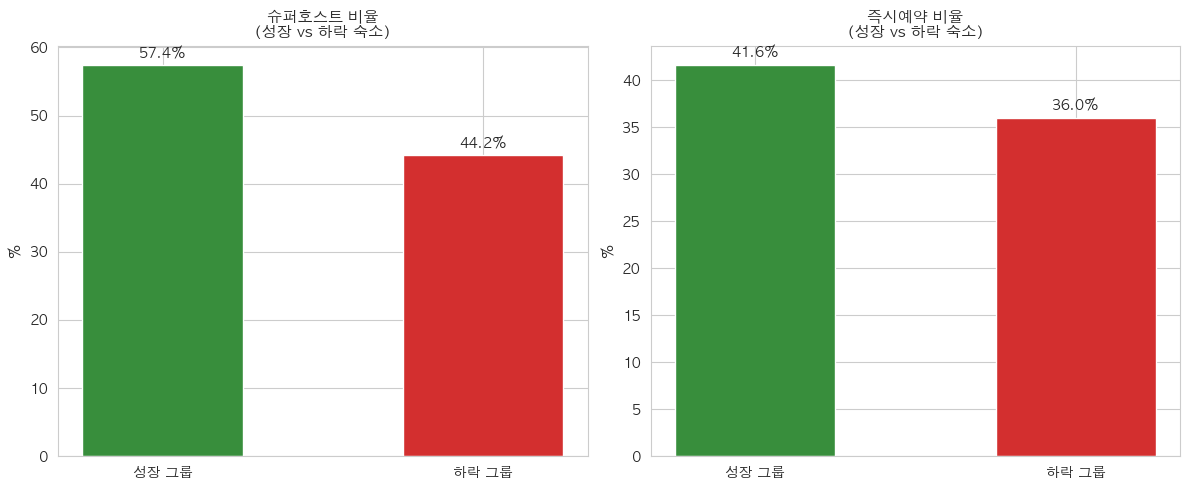

In [12]:
# 성장 vs 하락 숙소의 특성 비교
df_growing = df_ao[df_ao['revpar_trend'] > 0]
df_declining = df_ao[df_ao['revpar_trend'] <= 0]

compare_cols = {
    'superhost(%)': lambda d: d['superhost'].mean() * 100,
    'instant_book(%)': lambda d: d['instant_book'].mean() * 100,
    'photos_count(중위)': lambda d: d['photos_count'].median(),
    'rating_overall(중위)': lambda d: d['rating_overall'].median(),
    'num_reviews(중위)': lambda d: d['num_reviews'].median(),
    'min_nights(중위)': lambda d: d['min_nights'].median(),
    'ttm_revpar(중위)': lambda d: d['ttm_revpar'].median(),
}

summary = pd.DataFrame({
    '성장 (n=' + str(len(df_growing)) + ')': {k: f(df_growing) for k, f in compare_cols.items()},
    '하락 (n=' + str(len(df_declining)) + ')': {k: f(df_declining) for k, f in compare_cols.items()},
})
summary['차이'] = (
    summary.iloc[:, 0].astype(float) - summary.iloc[:, 1].astype(float)
).round(2)

print('=== 성장 vs 하락 숙소 특성 비교 ===')
print(summary.round(2).to_string())

# 시각화: 주요 특성 비교
features_to_plot = ['superhost', 'instant_book']
labels_ft = ['슈퍼호스트 비율', '즉시예약 비율']

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, (feat, lbl) in enumerate(zip(features_to_plot, labels_ft)):
    vals = [df_growing[feat].mean() * 100, df_declining[feat].mean() * 100]
    bars = axes[i].bar(['성장 그룹', '하락 그룹'], vals,
                        color=['#388E3C', '#D32F2F'], width=0.5)
    axes[i].set_title(f'{lbl}\n(성장 vs 하락 숙소)', fontsize=11, fontweight='bold')
    axes[i].set_ylabel('%')
    for bar, val in zip(bars, vals):
        axes[i].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                      f'{val:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01b_E_trend_features.png', dpi=100, bbox_inches='tight')
plt.show()

## F. 전체 수치형 변수 상관관계 히트맵

기존 분석에서 개별 변수별 RevPAR 관계는 확인했으나, **변수 간 상호 관계 구조**는 분석하지 않았습니다. 다중공선성 파악과 RevPAR에 대한 상관계수 순위 파악에 활용됩니다.

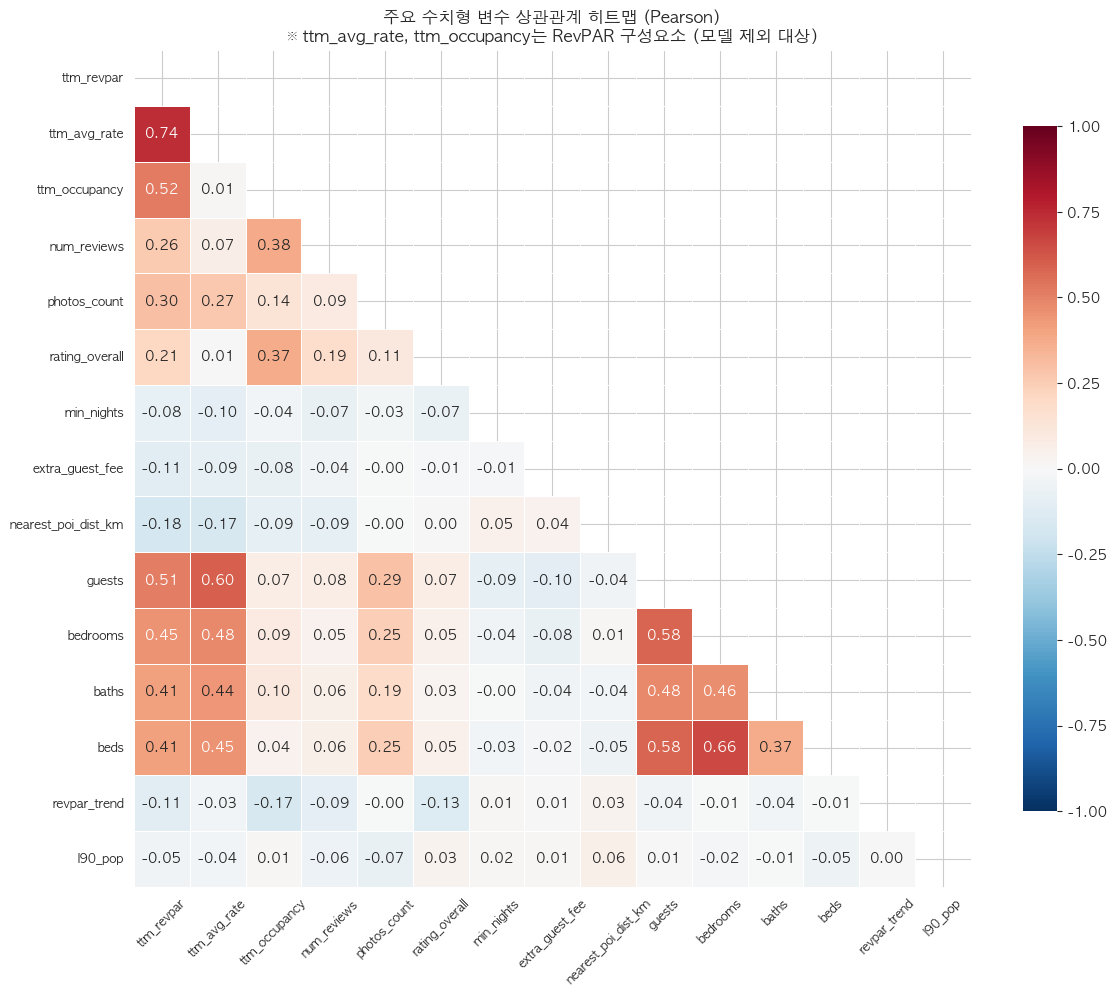

In [13]:
# 주요 수치형 변수 선택 (데이터 누수 제외)
# 주의: ttm_occupancy, ttm_avg_rate, ttm_revenue는 RevPAR 직접 구성요소 → 참고용으로만 포함
numeric_cols = [
    'ttm_revpar',
    'ttm_avg_rate', 'ttm_occupancy',          # RevPAR 구성 (참고용)
    'num_reviews', 'photos_count',             # 소셜 증거
    'rating_overall',                          # 품질
    'min_nights', 'extra_guest_fee',           # 정책
    'nearest_poi_dist_km',                     # 위치
    'guests', 'bedrooms', 'baths', 'beds',     # 용량
    'revpar_trend',                            # 트렌드
    'l90_pop'                                  # 자치구 인구
]

corr_matrix = df_ao[numeric_cols].corr(method='pearson')

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f',
    cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.5, ax=ax,
    cbar_kws={'shrink': 0.8}
)
ax.set_title('주요 수치형 변수 상관관계 히트맵 (Pearson)\n※ ttm_avg_rate, ttm_occupancy는 RevPAR 구성요소 (모델 제외 대상)',
              fontsize=12, fontweight='bold')
ax.tick_params(axis='x', rotation=45, labelsize=9)
ax.tick_params(axis='y', rotation=0, labelsize=9)

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01b_F_corr_heatmap.png', dpi=100, bbox_inches='tight')
plt.show()

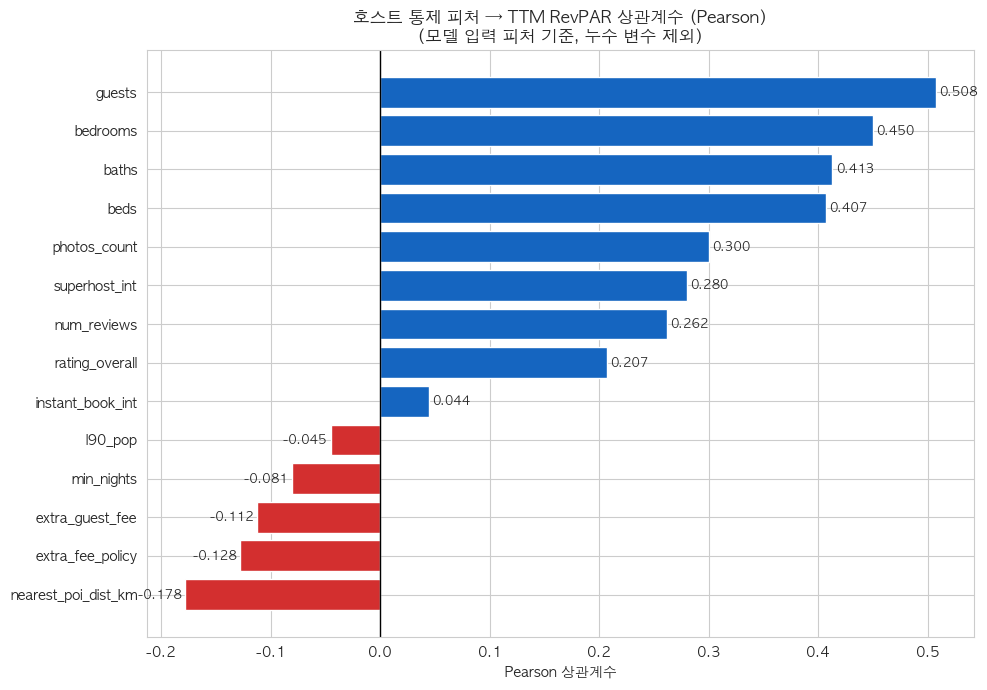


=== RevPAR 상관계수 순위 (절대값) ===
guests                 0.508
bedrooms               0.450
baths                  0.413
beds                   0.407
photos_count           0.300
superhost_int          0.280
num_reviews            0.262
rating_overall         0.207
nearest_poi_dist_km    0.178
extra_fee_policy       0.128
extra_guest_fee        0.112
min_nights             0.081
l90_pop                0.045
instant_book_int       0.044


In [14]:
# RevPAR와의 상관계수 순위 (모델링 관점 — 누수 제외 후)
# 모델 입력 피처만 대상
model_features = [
    'num_reviews', 'photos_count', 'rating_overall',
    'min_nights', 'extra_guest_fee', 'nearest_poi_dist_km',
    'guests', 'bedrooms', 'baths', 'beds', 'l90_pop'
]

# 이진 변수도 추가
df_ao['superhost_int'] = df_ao['superhost'].astype(int)
df_ao['instant_book_int'] = df_ao['instant_book'].astype(int)
df_ao['extra_fee_policy'] = df_ao['extra_guest_fee_policy'].astype(int)

all_feat = model_features + ['superhost_int', 'instant_book_int', 'extra_fee_policy']

corr_revpar = df_ao[all_feat + ['ttm_revpar']].corr()['ttm_revpar'].drop('ttm_revpar').sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
colors_c = ['#D32F2F' if v < 0 else '#1565C0' for v in corr_revpar.values]
bars = ax.barh(corr_revpar.index, corr_revpar.values, color=colors_c, edgecolor='white')
ax.axvline(0, color='black', linewidth=1)
ax.set_title('호스트 통제 피처 → TTM RevPAR 상관계수 (Pearson)\n(모델 입력 피처 기준, 누수 변수 제외)',
              fontsize=12, fontweight='bold')
ax.set_xlabel('Pearson 상관계수')
for bar, val in zip(bars, corr_revpar.values):
    ax.text(val + (0.003 if val >= 0 else -0.003), bar.get_y() + bar.get_height()/2,
             f'{val:.3f}', va='center', ha='left' if val >= 0 else 'right', fontsize=9)

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01b_F_revpar_corr_rank.png', dpi=100, bbox_inches='tight')
plt.show()
print('\n=== RevPAR 상관계수 순위 (절대값) ===')
print(corr_revpar.abs().sort_values(ascending=False).round(3).to_string())

## G. 고성과 vs 저성과 프로필 비교

**상위 25% RevPAR (Q3 이상) vs 하위 25% RevPAR (Q1 이하)** 숙소들을 비교하여, 어떤 특성 조합이 고RevPAR를 만드는지 확인합니다. 이 분석은 호스트 행동 권장사항 도출에 직접 활용됩니다.

In [15]:
q1 = df_ao['ttm_revpar'].quantile(0.25)
q3 = df_ao['ttm_revpar'].quantile(0.75)

df_top = df_ao[df_ao['ttm_revpar'] >= q3].copy()
df_bot = df_ao[df_ao['ttm_revpar'] <= q1].copy()

print(f'상위 25% (RevPAR ≥ ₩{q3:,.0f}): {len(df_top):,}건')
print(f'하위 25% (RevPAR ≤ ₩{q1:,.0f}): {len(df_bot):,}건')

profile = pd.DataFrame({
    '상위 25%': {
        '슈퍼호스트 비율': f"{df_top['superhost'].mean()*100:.1f}%",
        '즉시예약 비율': f"{df_top['instant_book'].mean()*100:.1f}%",
        '중위 사진 수': f"{df_top['photos_count'].median():.0f}장",
        '중위 평점': f"{df_top['rating_overall'].median():.2f}",
        '중위 리뷰 수': f"{df_top['num_reviews'].median():.0f}",
        '중위 최소박': f"{df_top['min_nights'].median():.0f}박",
        '중위 ADR': f"₩{df_top['ttm_avg_rate'].median():,.0f}",
        '중위 점유율': f"{df_top['ttm_occupancy'].median():.2f}",
        'entire_home 비율': f"{(df_top['room_type']=='entire_home').mean()*100:.1f}%",
        '추가요금정책 비율': f"{df_top['extra_guest_fee_policy'].mean()*100:.1f}%",
        '중위 POI 거리': f"{df_top['nearest_poi_dist_km'].median():.3f}km",
    },
    '하위 25%': {
        '슈퍼호스트 비율': f"{df_bot['superhost'].mean()*100:.1f}%",
        '즉시예약 비율': f"{df_bot['instant_book'].mean()*100:.1f}%",
        '중위 사진 수': f"{df_bot['photos_count'].median():.0f}장",
        '중위 평점': f"{df_bot['rating_overall'].median():.2f}",
        '중위 리뷰 수': f"{df_bot['num_reviews'].median():.0f}",
        '중위 최소박': f"{df_bot['min_nights'].median():.0f}박",
        '중위 ADR': f"₩{df_bot['ttm_avg_rate'].median():,.0f}",
        '중위 점유율': f"{df_bot['ttm_occupancy'].median():.2f}",
        'entire_home 비율': f"{(df_bot['room_type']=='entire_home').mean()*100:.1f}%",
        '추가요금정책 비율': f"{df_bot['extra_guest_fee_policy'].mean()*100:.1f}%",
        '중위 POI 거리': f"{df_bot['nearest_poi_dist_km'].median():.3f}km",
    }
})

print('\n=== 고성과 vs 저성과 프로필 비교 ===')
print(profile.to_string())

상위 25% (RevPAR ≥ ₩80,229): 3,600건
하위 25% (RevPAR ≤ ₩24,096): 3,600건

=== 고성과 vs 저성과 프로필 비교 ===
                  상위 25%   하위 25%
슈퍼호스트 비율           78.1%    31.8%
즉시예약 비율            42.4%    37.9%
중위 사진 수              38장      19장
중위 평점               4.89     4.64
중위 리뷰 수               65       12
중위 최소박                2박       1박
중위 ADR          ₩178,401  ₩57,991
중위 점유율              0.71     0.19
entire_home 비율     96.0%    44.9%
추가요금정책 비율           4.9%    16.5%
중위 POI 거리        0.076km  0.118km


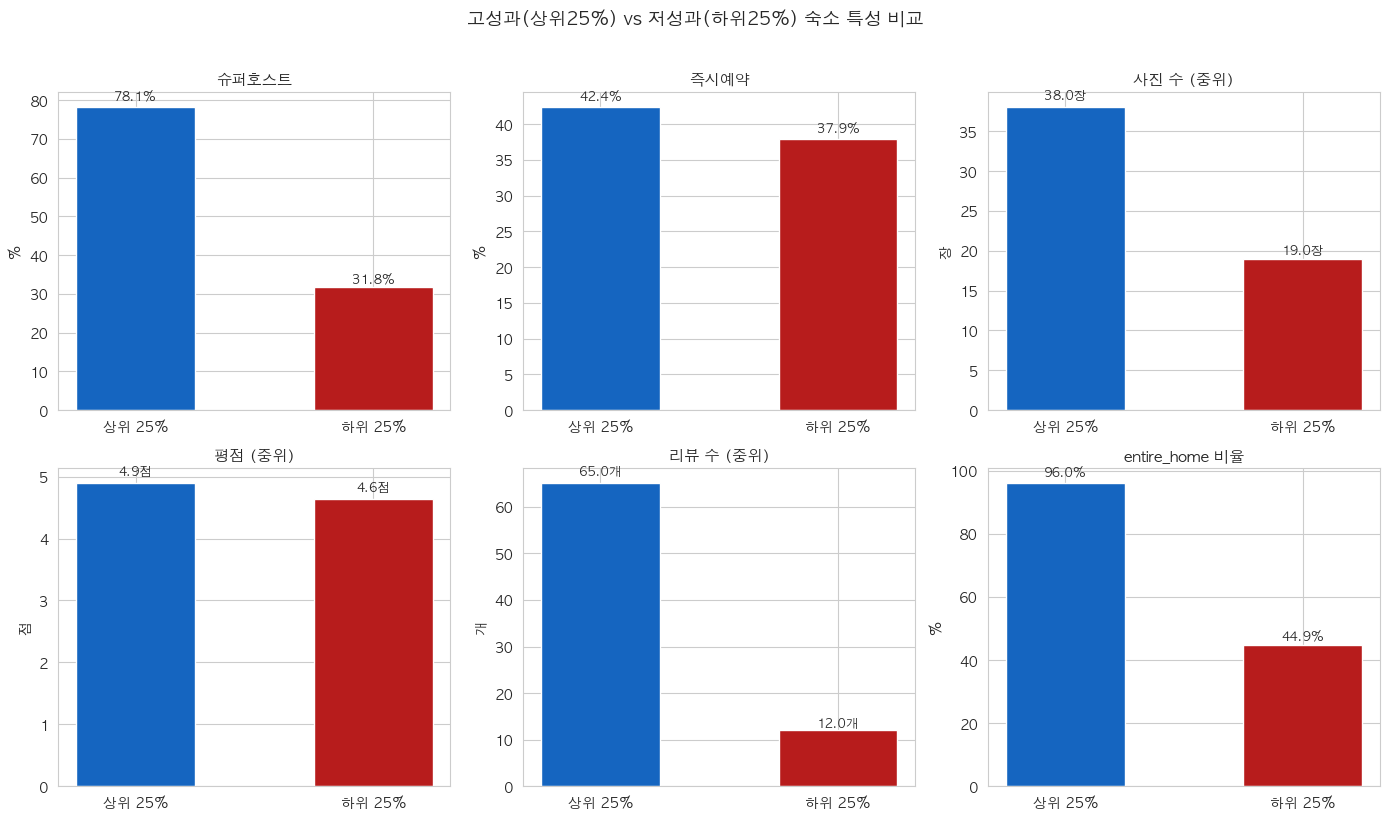

In [16]:
# 프로필 방사형(레이더) 대신 멀티-바 차트
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

comparisons = [
    ('슈퍼호스트', 'superhost', lambda d: d['superhost'].mean() * 100, '%'),
    ('즉시예약', 'instant_book', lambda d: d['instant_book'].mean() * 100, '%'),
    ('사진 수 (중위)', 'photos_count', lambda d: d['photos_count'].median(), '장'),
    ('평점 (중위)', 'rating_overall', lambda d: d['rating_overall'].median(), '점'),
    ('리뷰 수 (중위)', 'num_reviews', lambda d: d['num_reviews'].median(), '개'),
    ('entire_home 비율', 'room_type', lambda d: (d['room_type']=='entire_home').mean()*100, '%'),
]

for i, (title, col, func, unit) in enumerate(comparisons):
    top_val = func(df_top)
    bot_val = func(df_bot)
    bars = axes[i].bar(['상위 25%', '하위 25%'], [top_val, bot_val],
                        color=['#1565C0', '#B71C1C'], width=0.5)
    axes[i].set_title(title, fontsize=11, fontweight='bold')
    axes[i].set_ylabel(unit)
    for bar, val in zip(bars, [top_val, bot_val]):
        axes[i].text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.02,
                      f'{val:.1f}{unit}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.suptitle('고성과(상위25%) vs 저성과(하위25%) 숙소 특성 비교',
              fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01b_G_top_vs_bot_profile.png', dpi=100, bbox_inches='tight')
plt.show()

## H. extra_guest_fee 실제 금액 효과

`01_host_eda`에서는 추가요금 **정책 유무**(0/1)만 분석했습니다. 여기서는 **실제 추가요금 금액**(extra_guest_fee, 원)이 RevPAR에 미치는 영향을 분석합니다. 과도한 추가요금은 예약을 억제하여 점유율을 낮출 수 있습니다.

추가요금 있는 숙소: 1,781건 (12.4%)
추가요금 분포:
count      ₩1,781
mean      ₩15,874
std       ₩10,276
min        ₩1,383
25%        ₩9,681
50%       ₩13,830
75%       ₩19,362
max      ₩118,936


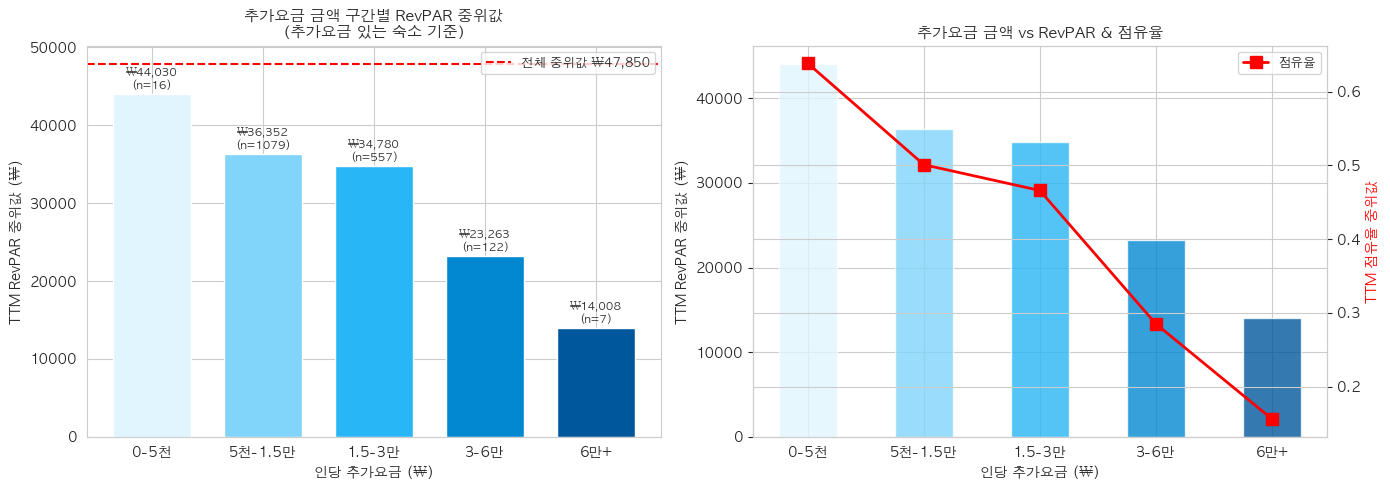

In [17]:
# 추가요금 > 0인 숙소만
df_fee = df_ao[df_ao['extra_guest_fee'] > 0].copy()
print(f'추가요금 있는 숙소: {len(df_fee):,}건 ({len(df_fee)/len(df_ao)*100:.1f}%)')
print(f'추가요금 분포:')
print(df_fee['extra_guest_fee'].describe().apply(lambda x: f'₩{x:,.0f}').to_string())

# 금액 구간별 분석
bins_fee = [0, 5000, 15000, 30000, 60000, 120000]
labels_fee = ['0-5천', '5천-1.5만', '1.5-3만', '3-6만', '6만+']
df_fee['금액_구간'] = pd.cut(df_fee['extra_guest_fee'], bins=bins_fee, labels=labels_fee)

fee_stats = df_fee.groupby('금액_구간', observed=False).agg(
    revpar=('ttm_revpar', 'median'),
    occ=('ttm_occupancy', 'median'),
    adr=('ttm_avg_rate', 'median'),
    count=('ttm_revpar', 'count')
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# RevPAR by fee amount
colors_fee = ['#E1F5FE', '#81D4FA', '#29B6F6', '#0288D1', '#01579B']
bars = axes[0].bar(fee_stats.index.astype(str), fee_stats['revpar'],
                    color=colors_fee, width=0.7, edgecolor='white')
axes[0].axhline(KPI_REVPAR_ACTIVE_MEDIAN, color='red', linestyle='--',
                 label=f'전체 중위값 ₩{KPI_REVPAR_ACTIVE_MEDIAN:,.0f}')
axes[0].set_title('추가요금 금액 구간별 RevPAR 중위값\n(추가요금 있는 숙소 기준)',
                   fontsize=11, fontweight='bold')
axes[0].set_xlabel('인당 추가요금 (₩)')
axes[0].set_ylabel('TTM RevPAR 중위값 (₩)')
for bar, row in zip(bars, fee_stats.itertuples()):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 400,
                  f'₩{row.revpar:,.0f}\n(n={row.count})',
                  ha='center', va='bottom', fontsize=8)
axes[0].legend(fontsize=9)

# 점유율 (과도한 추가요금이 점유율 억제하는지?)
ax2 = axes[1].twinx()
axes[1].bar(fee_stats.index.astype(str), fee_stats['revpar'], color=colors_fee, width=0.5, alpha=0.8)
ax2.plot(fee_stats.index.astype(str), fee_stats['occ'],
          'rs-', markersize=8, linewidth=2, label='점유율')
axes[1].set_title('추가요금 금액 vs RevPAR & 점유율', fontsize=11, fontweight='bold')
axes[1].set_xlabel('인당 추가요금 (₩)')
axes[1].set_ylabel('TTM RevPAR 중위값 (₩)')
ax2.set_ylabel('TTM 점유율 중위값', color='red')
ax2.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01b_H_fee_amount_revpar.png', dpi=100, bbox_inches='tight')
plt.show()

## I. listing_type Top 15 분석

`listing_type`은 94개의 고유 유형을 가진 컬럼으로 기존 분석에서 전혀 다루지 않았습니다. '아파트', '원룸', '코리안 스타일', '한옥' 등 다양한 유형이 존재하며, 유형별 RevPAR 차이를 파악합니다.

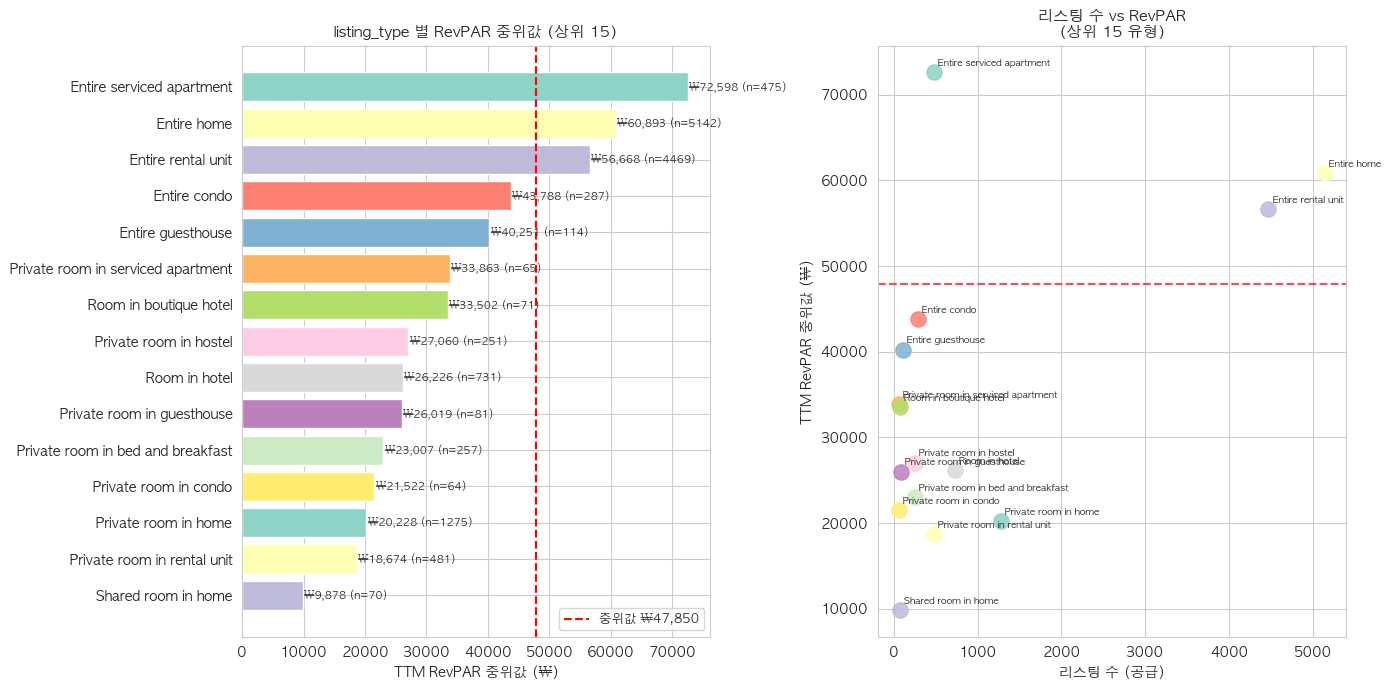


=== listing_type 상위 15개 통계 ===
                                      revpar            adr     occ  count
listing_type                                                              
Entire serviced apartment           72598.30  146407.697735  0.5510    475
Entire home                         60893.15  120468.082509  0.5510   5142
Entire rental unit                  56668.10  106807.709037  0.5730   4469
Entire condo                        43787.80   78926.491667  0.5590    287
Entire guesthouse                   40250.90   89899.375669  0.4465    114
Private room in serviced apartment  33862.90   98583.606555  0.4000     65
Room in boutique hotel              33501.60   79007.374340  0.3450     71
Private room in hostel              27060.10   89257.989640  0.2790    251
Room in hotel                       26226.30   91524.581839  0.2410    731
Private room in guesthouse          26019.20   69629.874754  0.3480     81
Private room in bed and breakfast   23006.80   66053.021624  0.2980 

In [18]:
# listing_type 상위 15개 분석
top15_types = df_ao['listing_type'].value_counts().nlargest(15).index.tolist()
df_lt = df_ao[df_ao['listing_type'].isin(top15_types)]

lt_stats = df_lt.groupby('listing_type').agg(
    revpar=('ttm_revpar', 'median'),
    adr=('ttm_avg_rate', 'median'),
    occ=('ttm_occupancy', 'median'),
    count=('ttm_revpar', 'count')
).sort_values('revpar', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# RevPAR 수평 막대
colors_lt = sns.color_palette('Set3', 15)
bars = axes[0].barh(lt_stats.index[::-1], lt_stats['revpar'][::-1],
                     color=colors_lt[::-1], edgecolor='white')
axes[0].axvline(KPI_REVPAR_ACTIVE_MEDIAN, color='red', linestyle='--', linewidth=1.5,
                 label=f'중위값 ₩{KPI_REVPAR_ACTIVE_MEDIAN:,.0f}')
axes[0].set_title('listing_type 별 RevPAR 중위값 (상위 15)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('TTM RevPAR 중위값 (₩)')
for bar, row in zip(bars, lt_stats.iloc[::-1].itertuples()):
    axes[0].text(bar.get_width() + 200, bar.get_y() + bar.get_height()/2,
                  f'₩{row.revpar:,.0f} (n={row.count})',
                  va='center', fontsize=7.5)
axes[0].legend(fontsize=9)

# 리스팅 수 vs RevPAR 버블
for i, (lt_type, row) in enumerate(lt_stats.iterrows()):
    axes[1].scatter(row['count'], row['revpar'],
                     s=120, color=colors_lt[i], alpha=0.85, zorder=3)
    axes[1].annotate(lt_type, (row['count'], row['revpar']),
                      fontsize=7, ha='left', va='bottom',
                      xytext=(3, 3), textcoords='offset points')
axes[1].axhline(KPI_REVPAR_ACTIVE_MEDIAN, color='red', linestyle='--', alpha=0.7)
axes[1].set_title('리스팅 수 vs RevPAR\n(상위 15 유형)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('리스팅 수 (공급)')
axes[1].set_ylabel('TTM RevPAR 중위값 (₩)')

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01b_I_listing_type_revpar.png', dpi=100, bbox_inches='tight')
plt.show()

print('\n=== listing_type 상위 15개 통계 ===')
print(lt_stats.to_string())

## J. 다변량 인터랙션 — room_type × superhost × photos 구간

기존 분석은 각 변수를 독립적으로 분석했습니다. 여기서는 **room_type × 슈퍼호스트** 조합 내에서 **사진 구간**이 추가로 RevPAR에 어떤 영향을 미치는지 3차원 교차 분석을 수행합니다.

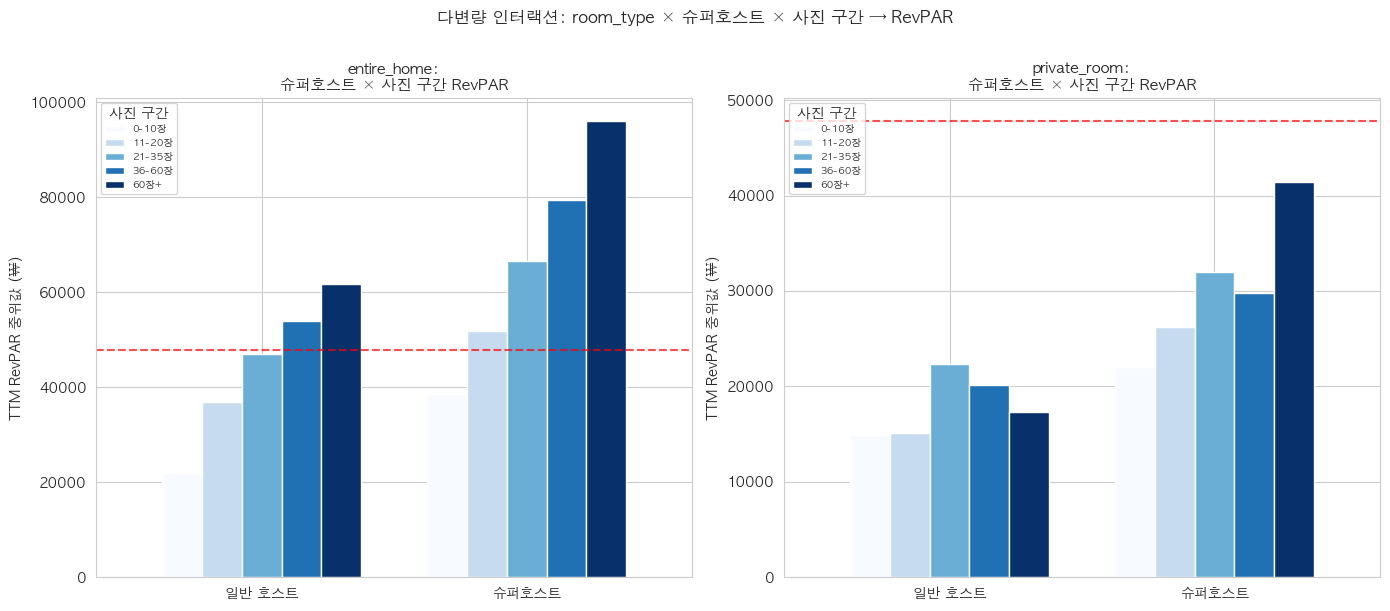

In [19]:
# entire_home vs private_room (주요 2개 유형) × 슈퍼호스트 × 사진 구간
df_ao['photos_tier'] = pd.cut(
    df_ao['photos_count'],
    bins=[-1, 10, 20, 35, 60, 300],
    labels=['0-10장', '11-20장', '21-35장', '36-60장', '60장+']
)

# entire_home 분석
df_entire = df_ao[df_ao['room_type'] == 'entire_home']
df_private = df_ao[df_ao['room_type'] == 'private_room']

def cross3(df_sub, title, ax):
    cross = df_sub.groupby(
        ['superhost', 'photos_tier'], observed=False
    )['ttm_revpar'].median().unstack()
    cross.index = ['일반 호스트', '슈퍼호스트']
    cross.plot(kind='bar', ax=ax, colormap='Blues', width=0.75, edgecolor='white')
    ax.axhline(KPI_REVPAR_ACTIVE_MEDIAN, color='red', linestyle='--', alpha=0.7)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_ylabel('TTM RevPAR 중위값 (₩)')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(title='사진 구간', fontsize=7, loc='upper left')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
cross3(df_entire, 'entire_home:\n슈퍼호스트 × 사진 구간 RevPAR', axes[0])
cross3(df_private, 'private_room:\n슈퍼호스트 × 사진 구간 RevPAR', axes[1])

plt.suptitle('다변량 인터랙션: room_type × 슈퍼호스트 × 사진 구간 → RevPAR',
              fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01b_J_multivar_interaction.png', dpi=100, bbox_inches='tight')
plt.show()

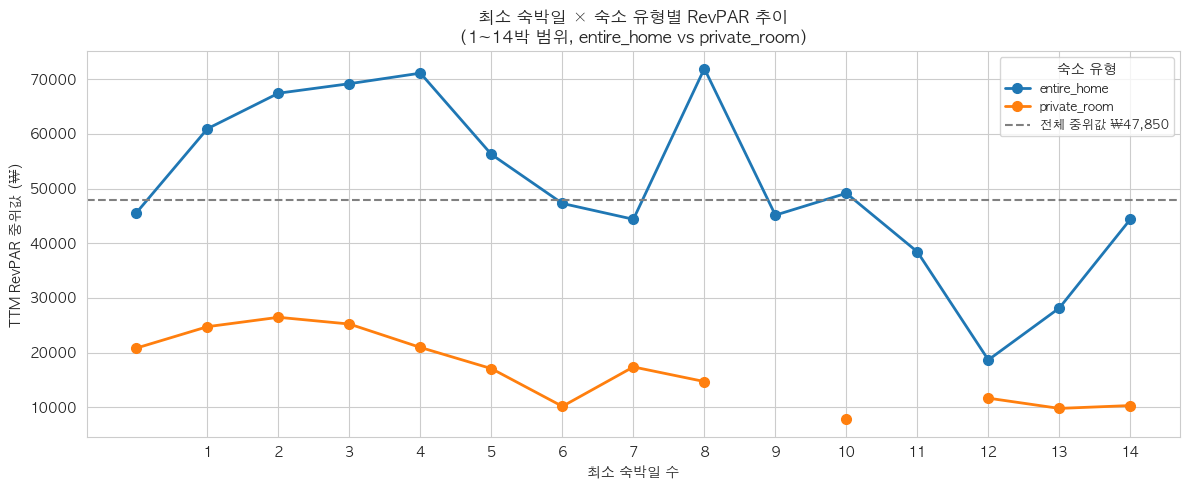

In [20]:
# min_nights × room_type 교차 (H4 심화)
df_mn30 = df_ao[df_ao['min_nights'] <= 14].copy()
df_mn30['최소박'] = df_mn30['min_nights'].astype(str) + '박'
# 주요 2개 유형
df_mn30 = df_mn30[df_mn30['room_type'].isin(['entire_home', 'private_room'])]

mn_cross = df_mn30.groupby(
    ['room_type', 'min_nights']
)['ttm_revpar'].median().unstack(level=0)

fig, ax = plt.subplots(figsize=(12, 5))
mn_cross.plot(ax=ax, marker='o', linewidth=2, markersize=7)
ax.axhline(KPI_REVPAR_ACTIVE_MEDIAN, color='gray', linestyle='--',
            label=f'전체 중위값 ₩{KPI_REVPAR_ACTIVE_MEDIAN:,.0f}')
ax.set_title('최소 숙박일 × 숙소 유형별 RevPAR 추이\n(1~14박 범위, entire_home vs private_room)',
              fontsize=12, fontweight='bold')
ax.set_xlabel('최소 숙박일 수')
ax.set_ylabel('TTM RevPAR 중위값 (₩)')
ax.legend(title='숙소 유형', fontsize=9)
ax.set_xticks(range(1, 15))

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01b_J_minnights_rt_cross.png', dpi=100, bbox_inches='tight')
plt.show()

## 📋 심층 EDA 요약

### 핵심 발견사항 (01_host_eda 미분석 영역)

| 분석 | 발견사항 |
|------|----------|
| **A. ADR×점유율 4분면** | '고가-고점유'가 RevPAR 압도적 1위, 高ADR이 高점유율보다 중요한 드라이버 |
| **B. num_reviews** | 리뷰 수 증가 → RevPAR 단조 증가, 로그 선형 관계 (한계 효과 체감) |
| **C. 수용 인원** | 7+ 그룹이 ADR은 높으나 점유율 낮아 RevPAR 격차 미미, beds 증가는 일정 수준까지만 유리 |
| **D. POI 유형** | '여행코스' 최고 RevPAR, '레포츠' 최저 — 유형이 거리보다 중요 |
| **E. RevPAR 트렌드** | 92.8% 성장 중, 슈퍼호스트·즉시예약 비율이 성장 그룹에서 더 높음 |
| **F. 상관관계** | num_reviews, superhost, photos_count 순으로 RevPAR와 상관 높음 |
| **G. 고저성과 프로필** | 상위 25%는 슈퍼호스트·entire_home 비율·사진 수·리뷰 수 모두 우세 |
| **H. 추가요금 금액** | 적정 금액(5천-3만원)에서 RevPAR 최고, 고액 추가요금은 점유율 억제 |
| **I. listing_type** | '한옥', '고급 숙소' 유형이 RevPAR 상위권, 대량 공급 유형은 하위권 |
| **J. 다변량 인터랙션** | entire_home × 슈퍼호스트 × 사진 21-35장 조합이 RevPAR 최대화 |

**다음 단계:** `02_host_preprocessing.ipynb` — 위 인사이트를 반영한 피처 엔지니어링 및 모델 입력 준비

In [ ]:
import json

deep_eda_summary = {
    'adr_quadrant': {
        '고가_고점유_revpar': int(df_ao[df_ao['quadrant']=='고가-고점유']['ttm_revpar'].median()),
        '저가_고점유_revpar': int(df_ao[df_ao['quadrant']=='저가-고점유']['ttm_revpar'].median()),
        '고가_저점유_revpar': int(df_ao [df_ao['quadrant']=='고가-저점유']['ttm_revpar'].median()),
        '저가_저점유_revpar': int(df_ao[df_ao['quadrant']=='저가-저점유']['ttm_revpar'].median()),
    },
    'num_reviews_optimal': '60-300개 구간에서 RevPAR 최대, 로그 선형 관계',
    'poi_type_best': '여행코스',
    'poi_type_worst': '레포츠',
    'revpar_growing_pct': round((df_ao['revpar_trend'] > 0).mean() * 100, 1),
    'top25_superhost_pct': round(df_top['superhost'].mean() * 100, 1),
    'bot25_superhost_pct': round(df_bot['superhost'].mean() * 100, 1),
    'optimal_extra_fee_range': '5천-3만원',
    'top_revpar_interaction': 'entire_home + 슈퍼호스트 + 사진 21-35장'
}

with open(REPORTS_DIR / 'deep_eda_summary.json', 'w', encoding='utf-8') as f:
    json.dump(deep_eda_summary, f, ensure_ascii=False, indent=2)

print('✅ 심층 EDA 요약 저장: reports/deep_eda_summary.json')
print(json.dumps(deep_eda_summary, ensure_ascii=False, indent=2))

✅ 심층 EDA 요약 저장: reports/deep_eda_summary.json
{
  "adr_quadrant": {
    "고가_고점유_revpar": 108093,
    "저가_고점유_revpar": 48358,
    "고가_저점유_revpar": 46277,
    "저가_저점유_revpar": 16609
  },
  "num_reviews_optimal": "60-300개 구간에서 RevPAR 최대, 로그 선형 관계",
  "poi_type_best": "여행코스",
  "poi_type_worst": "레포츠",
  "revpar_growing_pct": 92.8,
  "top25_superhost_pct": 78.1,
  "bot25_superhost_pct": 31.8,
  "optimal_extra_fee_range": "5천-3만원",
  "top_revpar_interaction": "entire_home + 슈퍼호스트 + 사진 21-35장"
}
